# Man Wayne Hui
# CUNY School Of Professional Studies
# Assignment #6 of Week 8

# Objective: Auto MPG Dataset Exploration

This project analyzes vehicle performance data across different eras, weight classes, and origins. We utilize:
- **`pandas`** for tabular data manipulation and loading.
- **`numpy`** for numerical handling and missing value representations (`np.nan`).
- **`matplotlib.pyplot`** and **`seaborn`** for distribution and correlation visualizations.

We configure `whitegrid` for clean, readable plots.

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

sb.set_theme(style="whitegrid")


## Attaching Column names

The `auto-mpg.data` file lacks a CSV-style comma structure and instead uses irregular whitespace separation between and it contains no header row.

- `sep=r'\s+'`: Matches one or more whitespace characters (tabs, spaces) to split fields cleanly.
- `names=column_names`: Directly maps the attributes detailed in `auto-mpg.names` onto the DataFrame indices.
- `.head()`: Checks the first 5 output rows to verifie that the columns and row values align correctly.

In [71]:
column_names = [
    'mpg',
    'cylinders',
    'displacement',
    'horsepower',
    'weight',
    'acceleration',
    'model_year',
    'origin',
    'car_name'
]


df = pd.read_csv('auto-mpg.data', sep=r'\s+', names=column_names)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## Data Type and Stats

Before altering the data, we assess its structural health:
1. **`df.info()`**: Shows non-null counts and current data types. Notice that `horsepower` is loaded as an `string` rather than a numerical type (`float64`). Also notice how we have 392 values instead of 398, meaning 6 of the values are missing or NaN.

2. **`df.describe()`**: Generates summary statistics across the chart, showing us if there are any bad data entries that might look off.

In [72]:

df.info()

df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


,mpg,cylinders,displacement,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


## Missing Values

In this dataset, missing entries in the `horsepower` attribute are filled with `'?'`.

To clean this:
1. `replace('?', np.nan)`: Replaces the string of `'?'` with `NaN` value so missing values recognized by pandas rather than treated as plain text characters.
2. `pd.to_numeric(...)`: Change the column into `float64` from string, unlocking continuous plotting and statistical operations.
3. Verification: 
    - Check `.isna().sum()` to confirm that exactly 6 records were cleanly tagged as missing values.
    - Check `.dtype` to ensure the column is now a float.

In [73]:

print("Count of '?' before replacement:", (df['horsepower'] == '?').sum())

df['horsepower'] = df['horsepower'].replace('?', np.nan)
df['horsepower'] = pd.to_numeric(df['horsepower'])

print("Missing values in horsepower now:", df['horsepower'].isna().sum())
print("Data type of horsepower:", df['horsepower'].dtype)

Count of '?' before replacement: 6
Missing values in horsepower now: 6
Data type of horsepower: float64


## Decoding Origins

The raw dataset codes regional vehicle origins as integers:
- 1 = USA
- 2 = Asia
- 3 = Europe

Using `df['origin'].map()`, we substitute integer codes with descriptive string labels. This allows Seaborn plot legends and axis labels to display human-readable categories automatically.

In [74]:
origin_mapping = {
    1: 'USA',
    2: 'Asia',
    3: 'Europe'
}

df['origin'] = df['origin'].map(origin_mapping)
df['origin'].value_counts()

origin
USA       249
Europe     79
Asia       70
Name: count, dtype: int64

## Engine Cylinders Bar Graph

We construct a discrete frequency bar chart using `sb.countplot()`.
- We can identify the dominant engine configurations such as 4/6/8 cylinders and locate rare variants like 3/5 cylinder.
- Plotting along the x-axis with a distinct color and labeled axes for clarity.

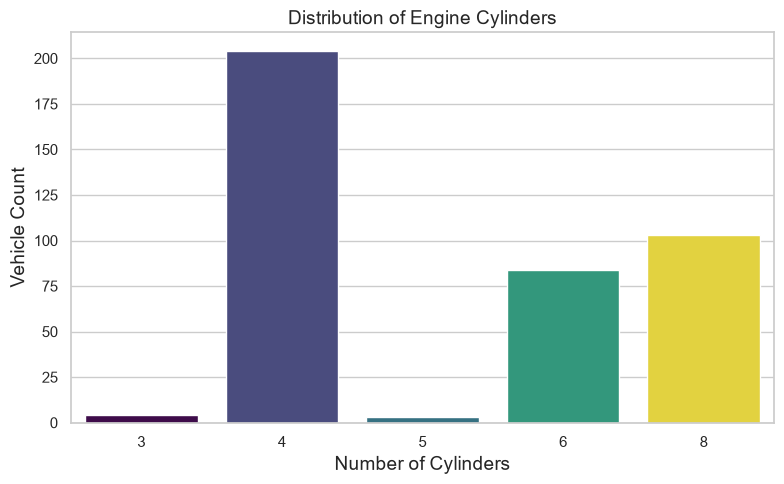

In [75]:
plt.figure(figsize=(8, 5))
sb.countplot(data=df, x='cylinders', hue='cylinders', palette='viridis', legend=False)

plt.title('Distribution of Engine Cylinders', fontsize=14)
plt.xlabel('Number of Cylinders', fontsize=14)
plt.ylabel('Vehicle Count', fontsize=14)
plt.tight_layout()
plt.show()

## Horsepower vs. Weight

We assess engine output relative to vehicle mass using `sb.scatterplot()`.
- `x='weight'`, `y='horsepower'`: Plots curb weight against engine output.
- `alpha=0.7`: Applies transparency to scatter points to make overlapping clusters distinguishable.
- Graph shows a upward trend that the heavier to vechile is the more horsepower power needed.

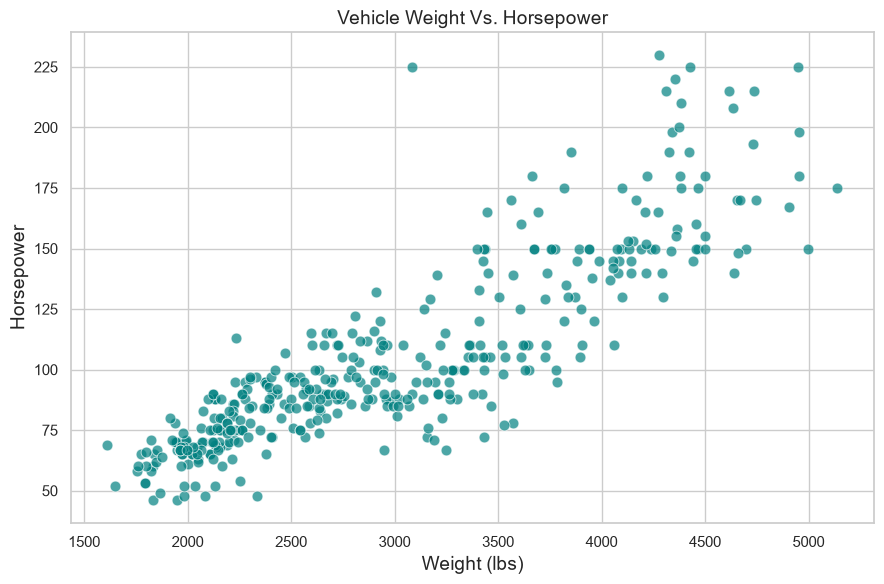

In [76]:
plt.figure(figsize=(9, 6))
sb.scatterplot(
    data=df,
    x='weight',
    y='horsepower',
    alpha=0.7,
    color='teal',
    edgecolor='w',
    s=60
)

plt.title('Vehicle Weight Vs. Horsepower', fontsize=14)
plt.xlabel('Weight (lbs)', fontsize=14)
plt.ylabel('Horsepower', fontsize=14)
plt.tight_layout()
plt.show()


### Research Question:
How does fuel economy (`mpg`) vary with `vehicle weight` across different (`origin`), and do vehicles maintain better fuel economy even at comparable weights?

### Answer:
Across all three regions, there is a clear negative correlation: as vehicle weight increases, fuel efficiency (`mpg`) decreases substantially. 

However, looking at the separation between trend lines and data points, we can draw two key conclusions:

1. When comparing vehicles within the overlapping light-to-midweight bracket around 2,000 to 3,000 lbs, vehicles from `Asia` and `Europe` consistently achieve higher MPG than `USA` vehicles of the exact same weight. Their regional trend lines sit noticeably higher on the vertical axis throughout this range.
2. The dataset also reveals strong regional serperation with US automakers produced almost all of the heavy vehicles over 3,000 lbs, which pulls the overall US average MPG down.As Asian and European automakers focused almost exclusively on compact, lightweight cars under 3,000 lbs, allowing them to dominate the high-efficiency end of the spectrum.

### As for reasons why:
- We can assume United States infrastructure focused expansive highway systems, long travel distances, and historically cheap gasoline. Which fostered consumer demand for larger, heavier, comforter vehicles. While Asia & Europe have typically higher fuel taxes, dense urban centers with narrower roadways which forced manufacturers to prioritize small, lightweight city cars for decades.

### Code Breakdown & Graph Setup
1. Canvas Setup (`plt.figure`):
   - `figsize=(10, 6)`: Creates a 10:6 aspect ratio of our graph.

2. The Base Scatterplot (`sb.scatterplot`):
   - `x='weight', y='mpg'`: Places `vehicle weight` on horizontal axis and `mph`along the vertical axis.
   - `hue='origin'`: Colors pointing to their region (`USA`, `Asia`, `Europe`).
   - `style='origin'`: Assigns a different marker shape (`circles`, `squares`, `crosses`) to each region.
   - `s=70`: Increases point marker size.
   - `alpha=0.85`: Adds slight transparency to make clusters of dense, overlapping vehicles clearly distinguishable.
   - `palette='Set1'`: Uses high-contrast, distinct colors for clear visual separation.

3. Regional Trend Lines (`sb.regplot` Loop):
   - `zip(['USA', 'Asia', 'Europe'], ['red', 'blue', 'green'])`: Corresponding color to regions.
   - `data=df[df['origin'] == origin]`: Filters the dataset down to one region at a time so Seaborn calculates an independent trend line for each geography.
   - `scatter=False`: Stop it from drawing a second set of dots already on top of the trend line.
   - `line_kws={'label': f'{origin} Trend', 'linewidth': 2}`: Customizes line.

4. Formatting:
   - `plt.title`, `plt.xlabel`, `plt.ylabel`: Provide clear, publication-quality labels and units (lbs, MPG).
   - `plt.legend(title='Origin / Trend')`: Compiles the region points and their corresponding trend lines into a unified key.
   - `plt.tight_layout()`: Automatically adjusts margins so labels don't get clipped.

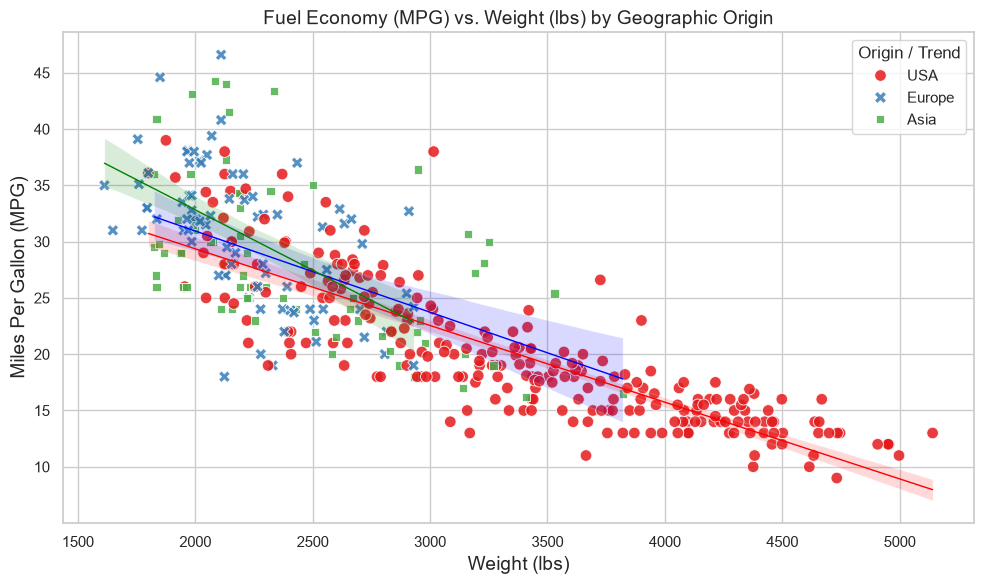

In [ ]:
plt.figure(figsize=(10, 6))

# Main Scatter Plot
sb.scatterplot(
    data=df,
    x='weight',
    y='mpg',
    hue='origin',
    style='origin',
    s=70,
    alpha=0.85,
    palette='Set1'
)

# Trend lines per origin region
for origin, color in zip(['USA', 'Asia', 'Europe'], ['red', 'blue', 'green']):
    sb.regplot(
        data=df[df['origin'] == origin],
        x='weight',
        y='mpg',
        scatter=False,
        color=color,
        line_kws={'label': f'{origin} Trend', 'linewidth': 2}
    )

plt.title('Fuel Economy (MPG) vs. Weight (lbs) by Geographic Origin', fontsize=14)
plt.xlabel('Weight (lbs)', fontsize=14)
plt.ylabel('Miles Per Gallon (MPG)', fontsize=14)
plt.legend(title='Origin / Trend')
plt.tight_layout()
plt.show()